In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## radar-chart

**Figure 3: Accuracy (%) of three 8–9B models on six benchmarks.** Numbers give our model's accuracy on each benchmark. Ours has the most balanced profile, with its largest gains on MATH (41.5 vs. 36.6 for the best baseline) and GSM8K (79.6 vs. 75.1).

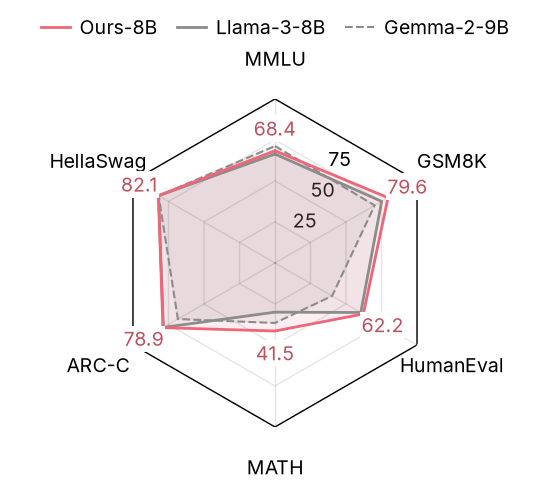

In [2]:
with open("../data/radar-chart.json") as f:
    data = json.load(f)
names = data["benchmarks"]
scores = data["scores"]
n = len(names)
angles = np.linspace(0, 2 * np.pi, n, endpoint=False)
loop = np.r_[angles, angles[:1]]
rings = [25, 50, 75, 100]

fig, ax = plt.subplots(figsize=(2.75, 2.75), subplot_kw={"projection": "polar"})
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)

ax.grid(False)
ax.spines["polar"].set_visible(False)
for r in rings:
    ax.plot(loop, [r] * (n + 1), color=colors["ink"], alpha=0.1, linewidth=0.5)
for a in angles:
    ax.plot([a, a], [0, rings[-1]], color=colors["ink"], alpha=0.1, linewidth=0.5)
ax.plot(loop, [rings[-1]] * (n + 1), color=colors["ink"], linewidth=0.5)
ax.set_ylim(0, rings[-1])

for name, linestyle, width in [("Llama-3-8B", "-", None), ("Gemma-2-9B", "--", paper.dashed_width)]:
    values = scores[name]
    ax.plot(loop, np.r_[values, values[:1]], color=colors["neutral"], linestyle=linestyle, linewidth=width, label=name)
    ax.fill(angles, values, color=colors["neutral"], alpha=0.1)

ours = scores["Ours-8B"]
ax.plot(loop, np.r_[ours, ours[:1]], color=colors["ours"], label="Ours-8B")
ax.fill(angles, ours, color=colors["ours"], alpha=0.1)
for a, v in zip(angles, ours):
    ax.annotate(f"{v:.3g}", (a, v), xytext=(8 * np.sin(a), 8 * np.cos(a)), textcoords="offset points",
                ha="center", va="center", color=darken(colors["ours"]),
                # the labels near 80 sit on the outer polygon, so a white box keeps them readable
                bbox=dict(facecolor="white", edgecolor="none", pad=0.5))

ax.set_xticks(angles, labels=names)
ax.tick_params(axis="x", pad=6)
ax.set_yticks([r * np.cos(np.pi / n) for r in rings[:-1]], labels=[str(r) for r in rings[:-1]])
ax.set_rlabel_position(180 / n)

handles, labels = ax.get_legend_handles_labels()
fig.legend(handles[::-1][:1] + handles[:2], labels[::-1][:1] + labels[:2],
           loc="outside upper center", ncol=3, frameon=False)

fit_height(fig, ax)
fig.savefig("../outputs/radar-chart.pdf")
fig.savefig("../outputs/radar-chart.png")
plt.show()